12 Aug 2025: added chromatic correction\
Image registration done using starfish method\
3rd Sep double check consistency with lm39_aml_starfish_run10_multifov.ipynb and save starfish output as CSV

In [1]:
from IPython import get_ipython
import matplotlib
import matplotlib.pyplot as plt

import os
# ---- Main folder = the repository folder, which holds Data/ (layout described in Data/README.md). ----
# Run this from the folder the file is in, or set the environment variable GUIDESTAR_MAIN_DIR to the repository path.
main_dir = os.environ.get('GUIDESTAR_MAIN_DIR', '../..')


matplotlib.rcParams["figure.dpi"] = 150

In [2]:
## Load data
import pprint
import starfish

### must load from local storage!
exp_json_path = os.path.join(main_dir, "Data/benchmarking/starfish/brain/LM50GS/primary/experiment.json")
experiment = starfish.Experiment.from_json(exp_json_path)

experiment

<starfish.Experiment (FOVs=86)>
{
fov_004: <starfish.FieldOfView>
  Primary Image: <slicedimage.TileSet (c: 1, z: 1, r: 16, x: 2048, y: 2048)>
  Auxiliary Images:
    
fov_005: <starfish.FieldOfView>
  Primary Image: <slicedimage.TileSet (c: 1, z: 1, r: 16, x: 2048, y: 2048)>
  Auxiliary Images:
    
fov_006: <starfish.FieldOfView>
  Primary Image: <slicedimage.TileSet (c: 1, z: 1, r: 16, x: 2048, y: 2048)>
  Auxiliary Images:
    
fov_007: <starfish.FieldOfView>
  Primary Image: <slicedimage.TileSet (c: 1, z: 1, r: 16, x: 2048, y: 2048)>
  Auxiliary Images:
    
  ...,
}

In [3]:
from starfish import FieldOfView
from starfish.types import Axes
from collections import defaultdict

pp = pprint.PrettyPrinter(indent=2)
pp.pprint(experiment._src_doc)
imgs = defaultdict()
for fov_data in experiment.fovs():
    print(fov_data.name)
    imgs[fov_data.name] = fov_data.get_image(FieldOfView.PRIMARY_IMAGES)
    
#imgs = experiment.fov().get_image(FieldOfView.PRIMARY_IMAGES)

{ 'codebook': 'codebook.json',
  'extras': {},
  'images': {'primary': 'primary.json'},
  'version': '5.0.0'}
fov_004
fov_005
fov_006
fov_007
fov_008
fov_009
fov_011
fov_012
fov_013
fov_014
fov_015
fov_016
fov_017
fov_018
fov_019
fov_020
fov_021
fov_022
fov_023
fov_025
fov_026
fov_027
fov_028
fov_029
fov_030
fov_031
fov_032
fov_033
fov_035
fov_036
fov_037
fov_038
fov_039
fov_040
fov_041
fov_042
fov_043
fov_044
fov_045
fov_047
fov_048
fov_049
fov_050
fov_051
fov_053
fov_054
fov_056
fov_057
fov_058
fov_059
fov_060
fov_061
fov_062
fov_063
fov_064
fov_065
fov_066
fov_067
fov_068
fov_069
fov_070
fov_071
fov_072
fov_073
fov_074
fov_076
fov_077
fov_078
fov_081
fov_082
fov_083
fov_085
fov_086
fov_087
fov_088
fov_089
fov_090
fov_091
fov_092
fov_093
fov_094
fov_095
fov_096
fov_097
fov_098
fov_099


In [4]:
imgs['fov_004'].sel({Axes.ROUND: 0, Axes.CH: 0, Axes.ZPLANE: 0}).xarray.data

100%|██████████| 16/16 [00:00<00:00, 46.21it/s]


array([[[[[0.073991  , 0.07486076, 0.0779736 , ..., 0.12469672,
           0.13705653, 0.13380636],
          [0.07313649, 0.07048142, 0.07385366, ..., 0.13347067,
           0.1295491 , 0.14306858],
          [0.07301442, 0.07547113, 0.07273976, ..., 0.1296254 ,
           0.1352407 , 0.13467613],
          ...,
          [0.06582742, 0.06321812, 0.05816739, ..., 0.11515984,
           0.10775921, 0.11494621],
          [0.06562905, 0.06343175, 0.06230259, ..., 0.10691997,
           0.11285572, 0.10919356],
          [0.06198215, 0.05748073, 0.06079194, ..., 0.11772335,
           0.11215381, 0.1119707 ]]]]], dtype=float32)

### Register, filter and scale raw data before decoding into spatially resolved gene expression

In [5]:
from skimage.transform import AffineTransform
import csv
import os
import re
import numpy as np
def parseDaybook(filepath: str,
                 verbose: bool = True,
                 ) -> AffineTransform:
    """
    parse daybook lateral chromatic shift output file
    and generate affine matrix

    returns affine matrix ready for warping with skimage
    """
    title_row = None
    values_row = None

    with open(filepath) as csv_file:

        csv_reader = csv.reader(csv_file, delimiter=';')

        for row in csv_reader:
            if "a_affine_parameter" in row:
                title_row = [title.strip() for title in row]
            # go to next row. then stop reading
            elif title_row is not None:
                values_row = [float(value) for value in row]
                break

    assert title_row is not None, "title row for param values not found in daybook csv file"
    assert values_row is not None, "row containing param values not found in daybook csv file"

    matrix = np.zeros((3, 3), dtype=np.float64)
    matrix[0, 0] = values_row[title_row.index("a_affine_parameter")]
    matrix[0, 1] = values_row[title_row.index("b_affine_parameter")]
    matrix[1, 0] = values_row[title_row.index("c_affine_parameter")]
    matrix[1, 1] = values_row[title_row.index("d_affine_parameter")]
    matrix[0, 2] = values_row[title_row.index("x_translation_affine_parameter")]
    matrix[1, 2] = values_row[title_row.index("y_translation_affine_parameter")]
    matrix[2, 2] = 1

    if verbose:
        print("____ Matrix: ____\n", matrix)

    return AffineTransform(matrix)

In [6]:
from starfish.image import Filter
from starfish.types import Levels
from skimage.transform import warp as skimage_warp
import numpy as np
from copy import deepcopy

type_to_colour = {
    "Cy3": "Cy3",
    "Alexa594": "Alexa594",
    "Cy5": "Cy5",
    "Cy7": "Cy7"
}
reference_colour = "Cy5"
calibration_path = os.path.join(main_dir, 'Data/20250728_Lm50GS_mbrain_3cT3/calibrationTriton')
color_list = ['Cy5', 'Cy7', 'Cy7', 'Cy7', 'Cy7', 'Cy5', 'Cy5', 'Cy7', 'Alexa594', 'Alexa594', 'Cy5', 'Cy5', 'Cy5', 'Alexa594', 'Alexa594', 'Alexa594']
dropped_bits = []
ref_bit = 0

params_pattern1 = re.compile("[a-zA-Z]+(\d+)_[a-zA-Z]+(\d+)")
params_pattern2 = re.compile("([a-zA-Z0-9]+)to([a-zA-Z0-9]+)")

pairs_tf_dict = {}

for file in os.listdir(calibration_path):

    if os.path.splitext(file)[-1] == ".csv":

        match1 = re.search(params_pattern1, file)
        match2 = re.search(params_pattern2, file)

        if match1:
            match = match1
        elif match2:
            match = match2
        else:
            continue

        daybook_fullpath = os.path.join(calibration_path, file)
        colour_pair = (match.group(1), match.group(2))

        pairs_tf_dict[colour_pair] = parseDaybook(daybook_fullpath)
colours_tf_dict = {reference_colour: None}
for pair in pairs_tf_dict:
    if pair[0] == reference_colour:
        colours_tf_dict[pair[1]] = pairs_tf_dict[pair]
    if pair[1] == reference_colour:
        colours_tf_dict[pair[0]] = pairs_tf_dict[pair].inverse


ghp = Filter.GaussianHighPass(sigma=3)
dpsf = Filter.DeconvolvePSF(num_iter=15, sigma=2, level_method=Levels.SCALE_SATURATED_BY_CHUNK)
glp = Filter.GaussianLowPass(sigma=1)

aligned_imgs = deepcopy(imgs)

low_passed = defaultdict()
for fov_key in imgs.keys():
    print(fov_key)
    
    img = imgs[fov_key]

    print("Chromatic correction...")
    
    for bit, selector in enumerate(img._iter_axes()):
        colour = color_list[bit]
        print(
            f"Correcting chromatic distortion for bit {bit} with colour {colour}...\n"
        )

        if bit not in dropped_bits:
            transform = colours_tf_dict[type_to_colour[colour]]
            if transform is not None:
                slice_to_warp = aligned_imgs[fov_key].sel({Axes.ROUND: bit, Axes.CH: 0, Axes.ZPLANE: 0}).xarray.squeeze().copy()
                align_slice = skimage_warp(slice_to_warp, transform)
                align_slice = np.expand_dims(align_slice, axis=0)
                aligned_imgs[fov_key].set_slice(selector, align_slice, [Axes.ZPLANE])
    
    print("Registering...")
    
    ref_img = aligned_imgs[fov_key].sel({Axes.ROUND: ref_bit, Axes.CH: 0, Axes.ZPLANE: 0})
    # print(f"Reference image: {ref_img}")
    
    # Register the image to the reference image using translation
    ltt = starfish.image.LearnTransform.Translation(
        reference_stack=ref_img,
        axes=Axes.ROUND,
        upsampling=1000,
    )
    transforms = ltt.run(aligned_imgs[fov_key])
    
    # print(f"transforms: {transforms}")

    warp = starfish.image.ApplyTransform.Warp()
    aligned_img = warp.run(
        stack=aligned_imgs[fov_key],
        transforms_list=transforms,
    )
    
    print("Filtering...")
    
    high_passed = ghp.run(aligned_img, verbose=True, in_place=False)
    
    # deconvolved = dpsf.run(high_passed, verbose=True, in_place=False)
    deconvolved = high_passed
    low_passed[fov_key] = glp.run(deconvolved, verbose=True, in_place=False,)

<>:19: SyntaxWarning: invalid escape sequence '\d'
<>:19: SyntaxWarning: invalid escape sequence '\d'
<user_home>\AppData\Local\Temp\ipykernel_67828\2677522166.py:19: SyntaxWarning: invalid escape sequence '\d'
  params_pattern1 = re.compile("[a-zA-Z]+(\d+)_[a-zA-Z]+(\d+)")


____ Matrix: ____
 [[ 1.00126148e+00  3.97436125e-05 -2.18404367e+00]
 [-3.97436125e-05  1.00126148e+00 -1.11771017e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
____ Matrix: ____
 [[ 1.00196723e+00  4.26314977e-05 -3.17444090e+00]
 [-4.26314977e-05  1.00196723e+00 -2.59335733e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
____ Matrix: ____
 [[ 9.97952527e-01  5.40682540e-07  2.15458376e+00]
 [-5.40682540e-07  9.97952527e-01  2.22519960e+00]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
fov_004
Chromatic correction...
Correcting chromatic distortion for bit 0 with colour Cy5...

Correcting chromatic distortion for bit 1 with colour Cy7...

Correcting chromatic distortion for bit 2 with colour Cy7...

Correcting chromatic distortion for bit 3 with colour Cy7...

Correcting chromatic distortion for bit 4 with colour Cy7...

Correcting chromatic distortion for bit 5 with colour Cy5...

Correcting chromatic distortion for bit 6 with colour Cy5...

Correcting chro

100%|██████████| 16/16 [00:00<00:00, 199.06it/s]


fov_005
Chromatic correction...
Correcting chromatic distortion for bit 0 with colour Cy5...

Correcting chromatic distortion for bit 1 with colour Cy7...



100%|██████████| 16/16 [00:00<00:00, 53.55it/s]


Correcting chromatic distortion for bit 2 with colour Cy7...

Correcting chromatic distortion for bit 3 with colour Cy7...

Correcting chromatic distortion for bit 4 with colour Cy7...

Correcting chromatic distortion for bit 5 with colour Cy5...

Correcting chromatic distortion for bit 6 with colour Cy5...

Correcting chromatic distortion for bit 7 with colour Cy7...

Correcting chromatic distortion for bit 8 with colour Alexa594...

Correcting chromatic distortion for bit 9 with colour Alexa594...

Correcting chromatic distortion for bit 10 with colour Cy5...

Correcting chromatic distortion for bit 11 with colour Cy5...

Correcting chromatic distortion for bit 12 with colour Cy5...

Correcting chromatic distortion for bit 13 with colour Alexa594...

Correcting chromatic distortion for bit 14 with colour Alexa594...

Correcting chromatic distortion for bit 15 with colour Alexa594...

Registering...
Filtering...


... (333 outputs left out)

fov_099
Chromatic correction...
Correcting chromatic distortion for bit 0 with colour Cy5...

Correcting chromatic distortion for bit 1 with colour Cy7...



100%|██████████| 16/16 [00:00<00:00, 50.17it/s]


Correcting chromatic distortion for bit 2 with colour Cy7...

Correcting chromatic distortion for bit 3 with colour Cy7...

Correcting chromatic distortion for bit 4 with colour Cy7...

Correcting chromatic distortion for bit 5 with colour Cy5...

Correcting chromatic distortion for bit 6 with colour Cy5...

Correcting chromatic distortion for bit 7 with colour Cy7...

Correcting chromatic distortion for bit 8 with colour Alexa594...

Correcting chromatic distortion for bit 9 with colour Alexa594...

Correcting chromatic distortion for bit 10 with colour Cy5...

Correcting chromatic distortion for bit 11 with colour Cy5...

Correcting chromatic distortion for bit 12 with colour Cy5...

Correcting chromatic distortion for bit 13 with colour Alexa594...

Correcting chromatic distortion for bit 14 with colour Alexa594...

Correcting chromatic distortion for bit 15 with colour Alexa594...

Registering...
Filtering...


100%|██████████| 16/16 [00:00<00:00, 243.01it/s]


In [7]:
aligned_imgs['fov_004'].sel({Axes.ROUND: 0, Axes.CH: 0, Axes.ZPLANE: 0}).xarray.data

array([[[[[0.073991  , 0.07486076, 0.0779736 , ..., 0.12469672,
           0.13705653, 0.13380636],
          [0.07313649, 0.07048142, 0.07385366, ..., 0.13347067,
           0.1295491 , 0.14306858],
          [0.07301442, 0.07547113, 0.07273976, ..., 0.1296254 ,
           0.1352407 , 0.13467613],
          ...,
          [0.06582742, 0.06321812, 0.05816739, ..., 0.11515984,
           0.10775921, 0.11494621],
          [0.06562905, 0.06343175, 0.06230259, ..., 0.10691997,
           0.11285572, 0.10919356],
          [0.06198215, 0.05748073, 0.06079194, ..., 0.11772335,
           0.11215381, 0.1119707 ]]]]], dtype=float32)

In [8]:
from starfish.types import Axes, Features
import numpy as np
from copy import deepcopy

filtered_imgs = deepcopy(low_passed)

In [10]:
# Compute global scale factor for each image based on the 99.9th percentile of pixel intensities
globalnorm_fovsubset = filtered_imgs.keys() #LM50GS - use all fovs for global normalization
per_image_percentile_cut = 99.9
pooled_percentile = 57
scale_list = []

for bit in range(len(color_list)):
    print(f"Processing bit {bit}...")
    selector = {Axes.ROUND: bit, Axes.CH: 0, Axes.ZPLANE: 0}
    intensity_pooled = [] # pool intensity holder for each bit
    for fov_key in filtered_imgs.keys():
        if fov_key in globalnorm_fovsubset:
            print(f"Processing FOV {fov_key}...")
            raw_array = filtered_imgs[fov_key].sel(selector).xarray.data # select the image for that bit and fov
            # following GS per_image_sample_method == "highest"
            cutoff = np.percentile(raw_array, per_image_percentile_cut)
            subsampled_array = raw_array[raw_array > cutoff]
            intensity_pooled.append(subsampled_array.flat)
    intensity_pooled = np.concatenate(intensity_pooled, axis=None)
    # following method == "median":
    bit_normalization_value = np.percentile(intensity_pooled, pooled_percentile) # get the 57th median of the all the 99.9th percentile intensities in the selected fovs       
    scale_list.append(bit_normalization_value)   

Processing bit 0...
Processing FOV fov_004...
Processing FOV fov_005...
Processing FOV fov_006...
Processing FOV fov_007...
Processing FOV fov_008...
Processing FOV fov_009...
Processing FOV fov_011...
Processing FOV fov_012...
Processing FOV fov_013...
Processing FOV fov_014...
Processing FOV fov_015...
Processing FOV fov_016...
Processing FOV fov_017...
Processing FOV fov_018...
Processing FOV fov_019...
Processing FOV fov_020...
Processing FOV fov_021...
Processing FOV fov_022...
Processing FOV fov_023...
Processing FOV fov_025...
Processing FOV fov_026...
Processing FOV fov_027...
Processing FOV fov_028...
Processing FOV fov_029...
Processing FOV fov_030...
Processing FOV fov_031...
Processing FOV fov_032...
Processing FOV fov_033...
Processing FOV fov_035...
Processing FOV fov_036...
Processing FOV fov_037...
Processing FOV fov_038...
Processing FOV fov_039...
Processing FOV fov_040...
Processing FOV fov_041...
Processing FOV fov_042...
Processing FOV fov_043...
Processing FOV fov

In [12]:
scale_factors = {}

for selector in filtered_imgs['fov_004']._iter_axes({Axes.ROUND, Axes.CH}):
    r = selector[Axes.ROUND]
    c = selector[Axes.CH]
    scale_factors[(r, c)] = scale_list[r]
scale_factors

{(0, 0): 0.05036450386047363,
 (1, 0): 0.015655264221131802,
 (2, 0): 0.02191262561827898,
 (3, 0): 0.020024462901055813,
 (4, 0): 0.015006552757695317,
 (5, 0): 0.041564814150333404,
 (6, 0): 0.048491997122764585,
 (7, 0): 0.017416661586612463,
 (8, 0): 0.025541831869632006,
 (9, 0): 0.010457400754094123,
 (10, 0): 0.051243869736790654,
 (11, 0): 0.04669615533202886,
 (12, 0): 0.03620764788240194,
 (13, 0): 0.011215181080624461,
 (14, 0): 0.023752757329493758,
 (15, 0): 0.023484739568084476}

In [13]:
for fov_key in low_passed.keys():
    
    print(f"scaling {fov_key}...")

    tmp_img = filtered_imgs[fov_key]

    for selector in tmp_img._iter_axes():
        # print(selector)
        data = tmp_img.get_slice(selector)[0]
        print(f"{fov_key} | shape: {data.shape}, dtype: {data.dtype}, min: {np.min(data)}, max: {np.max(data):0.2f}")
        scaled = data  / scale_factors[selector[Axes.ROUND.value], selector[Axes.CH.value]]
        scaled = np.clip(scaled, 0, 1)

        # print(scaled.shape, scaled.dtype, np.min(scaled), np.max(scaled))
        tmp_img.set_slice(selector, scaled, [Axes.ZPLANE])

scaling fov_004...
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.21
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.12
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.07
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.05
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.02
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.42
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.44
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.04
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.15
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.04
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.13
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.18
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.18
fov_004 | shape: (1, 2048, 2048), dtype: float32, min: 0.0, max: 0.04
f

# Save the mip of the scaled image

In [14]:
mip_save_path = os.path.join(main_dir, 'Data/benchmarking/starfish/brain/starfish_result/')
if not os.path.exists(mip_save_path):
    os.makedirs(mip_save_path)
for fov_key in filtered_imgs.keys():
    print(f"projecting {fov_key}...")
    projected_imgs = filtered_imgs[fov_key].reduce({Axes.CH}, func="max")
    np.save(mip_save_path + fov_key + '_projected.npy', projected_imgs.xarray.data)

projecting fov_004...


100%|██████████| 16/16 [00:00<00:00, 99.63it/s]


projecting fov_005...


100%|██████████| 16/16 [00:00<00:00, 86.30it/s]


projecting fov_006...


100%|██████████| 16/16 [00:00<00:00, 107.89it/s]


... (162 outputs left out)

projecting fov_098...


100%|██████████| 16/16 [00:00<00:00, 103.01it/s]


projecting fov_099...


100%|██████████| 16/16 [00:00<00:00, 106.21it/s]


In [15]:
from starfish.spots import DetectPixels

psd = DetectPixels.PixelSpotDecoder(
    codebook=experiment.codebook,
    metric='euclidean', # distance metric to use for computing distance between a pixel vector and a codeword
    norm_order=2, # the L_n norm is taken of each pixel vector and codeword before computing the distance. this is n
    distance_threshold=0.5176, # minimum distance between a pixel vector and a codeword for it to be called as a gene
    magnitude_threshold=.2, # discard any pixel vectors below this magnitude
    min_area=2, # do not call a 'spot' if it's area is below this threshold (measured in pixels)
    max_area=np.inf, # do not call a 'spot' if it's area is above this threshold (measured in pixels)
)

spot_intensities_all = defaultdict()

for fov_key in filtered_imgs.keys():
    
    print(f"Decoding {fov_key}...")
    
    initial_spot_intensities, prop_results = psd.run(filtered_imgs[fov_key])
    # display(initial_spot_intensities)
    spot_intensities = initial_spot_intensities.loc[initial_spot_intensities[Features.PASSES_THRESHOLDS]]
    # display(spot_intensities)
    spot_intensities_all[fov_key] = spot_intensities

Decoding fov_004...


100%|██████████| 9999/9999 [00:00<00:00, 26120.32it/s]


Decoding fov_005...


100%|██████████| 8715/8715 [00:00<00:00, 26135.34it/s]


Decoding fov_006...


100%|██████████| 9632/9632 [00:00<00:00, 23975.05it/s]


... (162 outputs left out)

Decoding fov_098...


100%|██████████| 22342/22342 [00:00<00:00, 24474.88it/s]


Decoding fov_099...


100%|██████████| 27948/27948 [00:00<00:00, 31358.78it/s]


In [16]:
import pandas as pd

results_all = pd.Series(dtype=int)
df_features = pd.DataFrame()

for fov, spots in spot_intensities_all.items():
    tmp_features = spots.to_features_dataframe()
    tmp_features['fov'] = fov
    tmp_features['mean_intensity'] = spots.mean(axis=1).data
    df_features = pd.concat([df_features, tmp_features], ignore_index=True)
    genes, counts = np.unique(spots[Features.AXIS][Features.TARGET], return_counts=True)
    result_counts = pd.Series(counts, index=genes)
    total_counts = result_counts.sum()
    print(f"FOV: {fov}, Total spots: {total_counts}")
    # display(result_counts)
    results_all = results_all.add(result_counts, fill_value=0).astype(int)

results_all.name = "total_counts_per_gene"

# display(results_all)
print(f"total number of genes found: {results_all.sum()}")

FOV: fov_004, Total spots: 6541
FOV: fov_005, Total spots: 5767
FOV: fov_006, Total spots: 6092
FOV: fov_007, Total spots: 8531
FOV: fov_008, Total spots: 14464
FOV: fov_009, Total spots: 16156
FOV: fov_011, Total spots: 6629
FOV: fov_012, Total spots: 6838
FOV: fov_013, Total spots: 16050
FOV: fov_014, Total spots: 19519
FOV: fov_015, Total spots: 14845
FOV: fov_016, Total spots: 9912
FOV: fov_017, Total spots: 7146
FOV: fov_018, Total spots: 6903
FOV: fov_019, Total spots: 10990
FOV: fov_020, Total spots: 9418
FOV: fov_021, Total spots: 17101
FOV: fov_022, Total spots: 11877
FOV: fov_023, Total spots: 5761
FOV: fov_025, Total spots: 3730
FOV: fov_026, Total spots: 13748
FOV: fov_027, Total spots: 15651
FOV: fov_028, Total spots: 10771
FOV: fov_029, Total spots: 6379
FOV: fov_030, Total spots: 11924
FOV: fov_031, Total spots: 5486
FOV: fov_032, Total spots: 1887
FOV: fov_033, Total spots: 3499
FOV: fov_035, Total spots: 4528
FOV: fov_036, Total spots: 4825
FOV: fov_037, Total spots: 2

In [17]:
df_features.to_csv(mip_save_path+ "lm50GS_brain_starfish_multifov.csv", index=False)

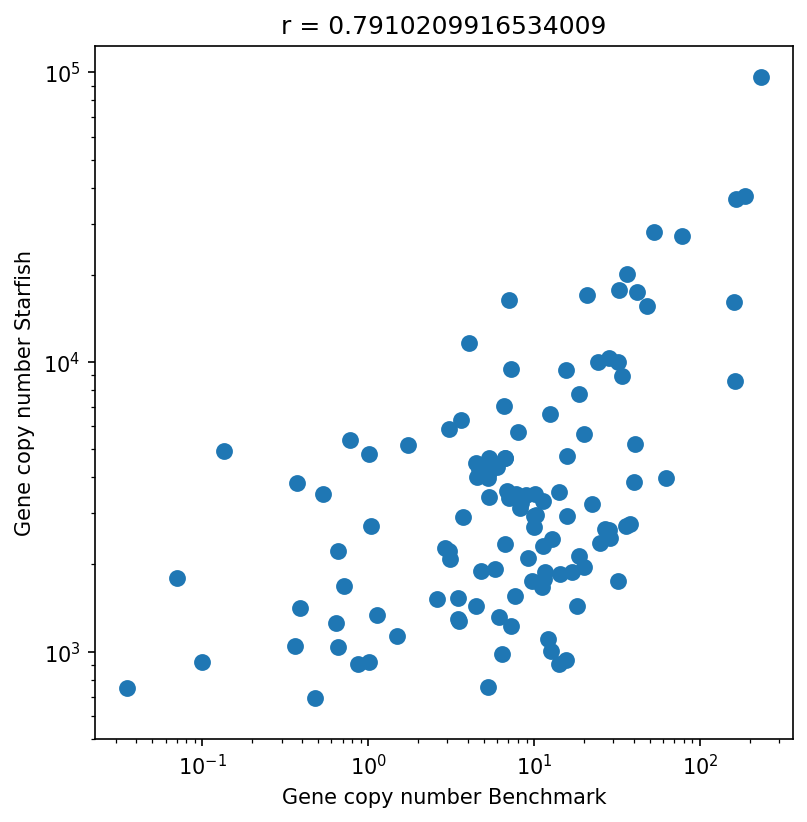

In [18]:
fpkm_path = os.path.join(main_dir, 'Data/20250728_Lm50GS_mbrain_3cT3/codebook/fpkm_data.txt')
bulk_fpkm = pd.read_csv(fpkm_path, sep='\t', index_col=0, header=None)

# display(bulk_fpkm)

comparison_df = pd.concat([results_all, bulk_fpkm], join='inner', axis=1)

# display(comparison_df)

tmp=comparison_df.values

r = np.corrcoef(tmp[:, 1], tmp[:, 0])[0, 1]
x = np.linspace(50, 2000)
f, ax = plt.subplots(figsize=(6, 6))
ax.scatter(tmp[:, 1], tmp[:, 0], 50, zorder=2)
# ax.plot(x, x, '-k', zorder=1)

plt.xlabel('Gene copy number Benchmark')
plt.ylabel('Gene copy number Starfish')
plt.xscale('log')
plt.yscale('log')
plt.title(f'r = {r}');


In [19]:
df_features[df_features['passes_thresholds']==False]

,z,y,x,target,radius,spot_id,distance,passes_thresholds,features,xc,yc,zc,fov,mean_intensity
